# Análise exploratória: acidentes de trânsito em Porto Alegre (M8)

Objetivo: conhecer a base aberta da Prefeitura (#DataPoa / EPTC) e escolher o valor de **N** da RN-01
(um local é crítico quando tem N ou mais acidentes num raio de 100 m).

Pré-requisito: rodar a carga (`cd backend && python -m app.ingestao --baixar`). O notebook lê o CSV
original para as checagens de colunas e o banco já limpo para o resto.

In [1]:
import sys, json
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "backend"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from app import banco, consultas, ingestao, pontos_criticos
from app.config import CAMINHO_BANCO, PASTA_RAW, RAIO_METROS

TINTA, CINZA, PAPEL, AZUL = "#1B2A33", "#5C6B73", "#EEF0EC", "#1F5A8A"
plt.rcParams.update({
    "figure.facecolor": PAPEL, "axes.facecolor": PAPEL, "axes.edgecolor": CINZA,
    "axes.labelcolor": TINTA, "xtick.color": CINZA, "ytick.color": CINZA, "text.color": TINTA,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#D5D9D5",
    "grid.linewidth": 0.6, "axes.axisbelow": True, "figure.figsize": (9, 3.6), "font.size": 10,
})

## 1. Arquivo original: colunas, tamanho e dados pessoais

In [2]:
bruto = ingestao.ler_csv(PASTA_RAW / "cat_acidentes.csv")
print(f"{len(bruto):,} registros e {bruto.shape[1]} colunas".replace(",", "."))
print("Extração:", bruto["data_extracao"].max())
print(list(bruto.columns))

87.323 registros e 34 colunas
Extração: 2026-10-01 01:34:51
['data_extracao', 'predial1', 'queda_arr', 'data', 'feridos', 'feridos_gr', 'mortes', 'morte_post', 'fatais', 'auto', 'taxi', 'lotacao', 'onibus_urb', 'onibus_met', 'onibus_int', 'caminhao', 'moto', 'carroca', 'bicicleta', 'outro', 'cont_vit', 'ups', 'patinete', 'idacidente', 'longitude', 'latitude', 'log1', 'log2', 'tipo_acid', 'dia_sem', 'hora', 'noite_dia', 'regiao', 'consorcio']


**LGPD.** As colunas são contagens de veículos e vítimas, endereço do acidente (logradouro e número predial),
tipo, data e hora. Não há nome, CPF, placa nem outra identificação de pessoas. A ingestão, mesmo assim,
remove essas colunas se um dia aparecerem (`limpeza.COLUNAS_PESSOAIS`).

In [3]:
pessoais = [c for c in bruto.columns if c.lower() in ("nome", "cpf", "rg", "placa", "cnh", "telefone")]
print("Colunas pessoais encontradas:", pessoais or "nenhuma")

Colunas pessoais encontradas: nenhuma


## 2. Carga e descartes (RN-02)

In [4]:
conn = banco.conectar(CAMINHO_BANCO)
carga = banco.ultima_carga(conn)
print(json.dumps(carga, ensure_ascii=False, indent=2))
print(f"Fora do mapa: {100 * carga['total_descartado'] / carga['total_lido']:.1f}% dos registros")

{
  "id": 2,
  "arquivo_origem": "cat_acidentes.csv",
  "data_carga": "2026-10-27T00:04:33",
  "total_lido": 87323,
  "total_aceito": 80175,
  "total_descartado": 7148,
  "descartes_por_motivo": {
    "sem_coordenada": 7144,
    "data_posterior_a_extracao": 4
  },
  "data_extracao": "2026-10-01"
}
Fora do mapa: 8.2% dos registros


In [5]:
todos = pd.read_sql_query("SELECT data, status, motivo_descarte FROM acidente", conn, parse_dates=["data"])
todos = todos[todos["motivo_descarte"].fillna("") != "data_posterior_a_extracao"]
cobertura = (todos.assign(ano=todos["data"].dt.year)
             .groupby("ano")["status"].apply(lambda s: 100 * (s == "valido").mean()).round(1))
cobertura.to_frame("% com coordenada válida")

,% com coordenada válida
ano,
2021,94.4
2022,95.7
2023,93.9
2024,91.3
2025,93.1
2026,81.0


A cobertura de coordenadas fica entre 91% e 96% de 2021 a 2025, o que confirma a suposição da seção 13 do escopo
("a maioria dos registros tem latitude e longitude"). Em 2026 ela cai para 81%. Hipótese, não confirmada:
os registros mais recentes ainda não foram todos georreferenciados pela EPTC. Vale comparar na próxima carga;
se for isso, a cobertura de 2026 sobe sozinha, e a Fase 2 (F5, geocodificação) pode recuperar o restante.

Quatro registros têm data posterior à extração (2027 a 2029) e são descartados como `data_posterior_a_extracao`.

## 3. Período e evolução

80.175 acidentes válidos, de 01/01/2021 a 30/09/2026


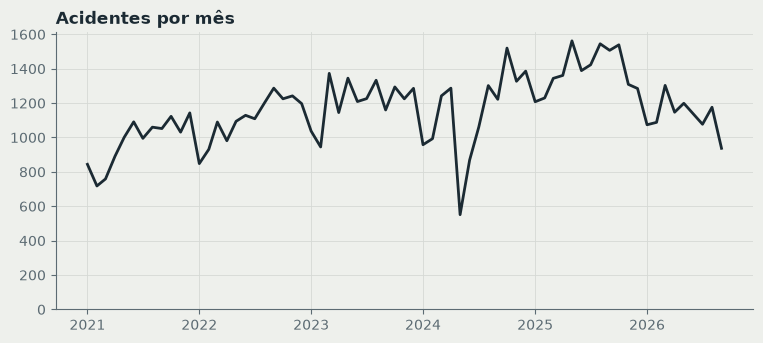

In [6]:
d = banco.ler_validos(conn)
print(f"{len(d):,}".replace(",", ".") + f" acidentes válidos, de {d['data'].min():%d/%m/%Y} a {d['data'].max():%d/%m/%Y}")
mensal = d.set_index("data").resample("MS").size()
fig, ax = plt.subplots()
ax.plot(mensal.index, mensal.values, color=TINTA, linewidth=2)
ax.set_title("Acidentes por mês", loc="left", fontweight="bold")
ax.set_ylim(bottom=0)
plt.show()

A base começa em janeiro de 2021, o que confirma a suposição de cobertura de 5 anos. O período padrão
do painel (RN-03) vai de 01/01/2021 até o registro mais recente.

## 4. Distribuição por horário, dia da semana e tipo de via

Sem horário: 810 registros (1.0%)


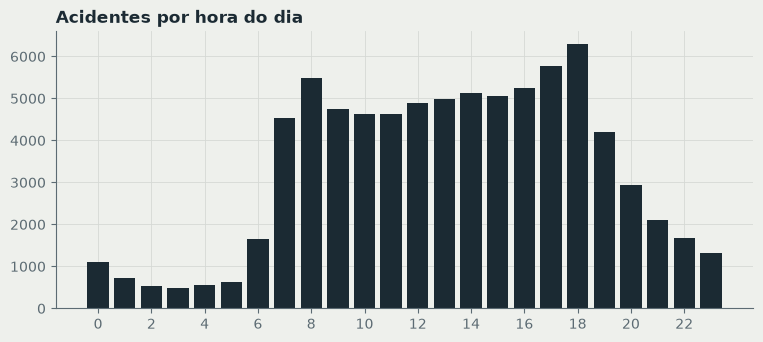

In [7]:
fig, ax = plt.subplots()
por_hora = d["hora_num"].value_counts().sort_index()
ax.bar(por_hora.index, por_hora.values, color=TINTA, width=0.8)
ax.set_xticks(range(0, 24, 2))
ax.set_title("Acidentes por hora do dia", loc="left", fontweight="bold")
plt.show()
print(f"Sem horário: {d['hora_num'].isna().sum()} registros ({100 * d['hora_num'].isna().mean():.1f}%)")

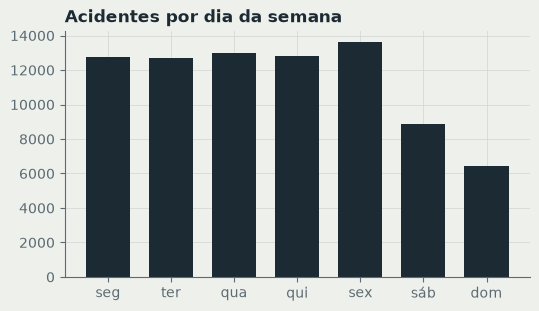

In [8]:
nomes_dias = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
por_dia = d["dia_semana"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(nomes_dias, por_dia.values, color=TINTA, width=0.7)
ax.set_title("Acidentes por dia da semana", loc="left", fontweight="bold")
plt.show()

In [9]:
siglas = d["log1"].str.split().str[0].value_counts()
print("Siglas de logradouro mais comuns:")
print(siglas.head(12).to_string())
via = d["tipo_via"].value_counts()
(100 * via / via.sum()).round(1).to_frame("% dos acidentes")

Siglas de logradouro mais comuns:
log1
AV      46930
R       28139
ESTR     3642
LG        289
PCA       261
TRAV      242
TUN       203
BC        176
AL        114
VDT        74
AC         42
VA          9


,% dos acidentes
tipo_via,
avenida,58.5
rua,35.1
estrada,4.5
outra,1.8


A base não tem campo de tipo de via, mas todo logradouro começa pela sigla oficial (AV, R, ESTR...).
Essa é a classificação já existente na base, usada pelo filtro (RN-05): avenida, rua, estrada e outras.
Não aparecem rodovias com sigla própria (RS, BR); a categoria fica disponível para quando surgirem.

In [10]:
pd.crosstab(d["gravidade"], d["tipo_via"], margins=True)

tipo_via,avenida,estrada,outra,rua,All
gravidade,,,,,
com_feridos,17269,1852,337,9345,28803
com_mortos,282,50,11,96,439
sem_vitimas,29379,1740,1116,18698,50933
All,46930,3642,1464,28139,80175


## 5. Concentração espacial: quantos vizinhos cada acidente tem a 100 m

Período padrão: 01/01/2021 a 30/09/2026, 80.175 acidentes
{'p25': 21, 'p50': 44, 'p75': 81, 'p90': 130, 'p95': 169, 'p99': 250}


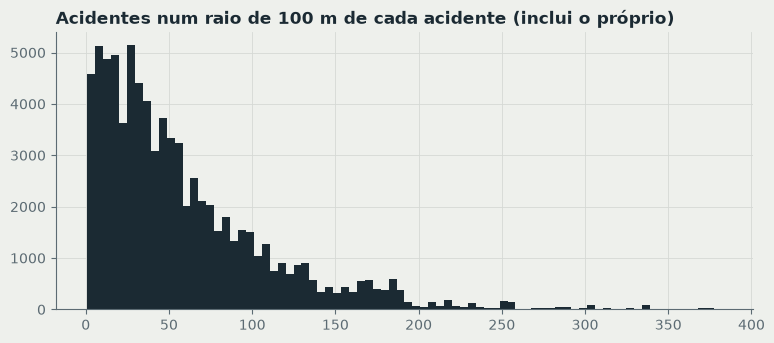

In [11]:
inicio, fim = consultas.periodo_padrao(d["data"])
padrao = consultas.aplicar(d, consultas.Filtros())
x, y = pontos_criticos.projetar(padrao["latitude"].to_numpy(), padrao["longitude"].to_numpy())
viz = pontos_criticos.vizinhos(x, y, RAIO_METROS)
contagem = np.array([len(v) for v in viz])
print(f"Período padrão: {inicio:%d/%m/%Y} a {fim:%d/%m/%Y}, " + f"{len(padrao):,}".replace(",", ".") + " acidentes")
print({f"p{p}": int(np.percentile(contagem, p)) for p in (25, 50, 75, 90, 95, 99)})
fig, ax = plt.subplots()
ax.hist(contagem, bins=80, color=TINTA)
ax.set_title("Acidentes num raio de 100 m de cada acidente (inclui o próprio)", loc="left", fontweight="bold")
plt.show()

Porto Alegre tem acidentes muito concentrados: o acidente típico tem dezenas de outros num raio de 100 m.
Por isso N precisa ser alto o bastante para separar esquinas de concentração persistente, mas não
tão alto que os filtros (um dia, um horário) deixem o mapa sem pontos.

## 6. Escolha de N

In [12]:
recortes = {
    "período padrão": consultas.Filtros(),
    "só sábados": consultas.Filtros(dias=(5,)),
    "noite (22h às 6h)": consultas.Filtros(hora_inicio=22, hora_fim=6),
    "só 2025": consultas.Filtros(inicio=pd.Timestamp("2025-01-01").date(), fim=pd.Timestamp("2025-12-31").date()),
    "só ruas": consultas.Filtros(vias=("rua",)),
}
candidatos = [5, 10, 15, 20, 25, 30, 40, 60]
linhas = {}
for nome, filtros in recortes.items():
    r = consultas.aplicar(d, filtros)
    linhas[nome] = [len(pontos_criticos.agrupar(r["latitude"].to_numpy(), r["longitude"].to_numpy(), RAIO_METROS, n))
                    for n in candidatos]
tabela = pd.DataFrame(linhas, index=pd.Index(candidatos, name="N")).T
tabela

N,5,10,15,20,25,30,40,60
período padrão,2599,1799,1370,1093,922,779,556,324
só sábados,562,199,77,32,10,3,1,0
noite (22h às 6h),400,145,65,24,12,9,0,0
só 2025,1037,501,260,160,96,54,19,2
só ruas,1371,810,520,373,276,215,124,48


In [13]:
grupos = {n: pontos_criticos.agrupar(padrao["latitude"].to_numpy(), padrao["longitude"].to_numpy(), RAIO_METROS, n)
          for n in candidatos}
coberto = pd.Series({n: 100 * sum(len(g) for g in grupos[n]) / len(padrao) for n in candidatos}).round(1)
coberto.to_frame("% dos acidentes dentro de algum ponto crítico")

,% dos acidentes dentro de algum ponto crítico
5,93.7
10,87.1
15,80.8
20,75.0
25,70.3
30,65.6
40,56.0
60,41.9


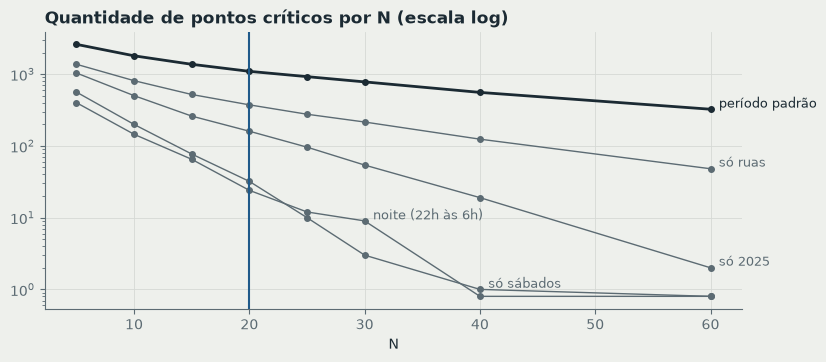

In [14]:
fig, ax = plt.subplots()
for nome in tabela.index:
    destaque = nome == "período padrão"
    valores = tabela.loc[nome].clip(lower=0.8)
    ax.plot(candidatos, valores, marker="o", markersize=4,
            color=TINTA if destaque else CINZA, linewidth=2 if destaque else 1)
    # Rótulo no último N com algum ponto, para as linhas que chegam a zero não se sobreporem.
    ultimo = max(i for i, v in enumerate(tabela.loc[nome]) if v > 0)
    ax.annotate(nome, (candidatos[ultimo], valores.iloc[ultimo]), xytext=(6, 4),
                textcoords="offset points", va="center", fontsize=9, color=TINTA if destaque else CINZA)
ax.axvline(20, color=AZUL, linewidth=1.5)
ax.set_yscale("log")
ax.set_xlabel("N")
ax.set_title("Quantidade de pontos críticos por N (escala log)", loc="left", fontweight="bold")
plt.show()

**Escolha: N = 20.**

- No período padrão, N = 20 gera cerca de 1.100 pontos e cobre três quartos dos acidentes. O ranking
  é ordenado do maior para o menor, então os primeiros lugares (mais de 300 acidentes) não mudam com N.
- Com N = 30 ou mais, filtros de uma dimensão quase zeram o mapa: "só sábados" fica com 3 pontos com N = 30,
  e "noite" com 9. Isso esvazia os filtros de horário e dia (RN-04).
- Com N = 10, o período padrão passa de 1.800 pontos e chega a 87% dos acidentes: quase tudo vira
  "crítico" e o termo perde valor.
- Em 5 anos e 9 meses de base, 20 acidentes no mesmo raio de 100 m equivalem a mais de um acidente
  registrado a cada 3,5 meses no mesmo local.

Recortes muito estreitos (sábado das 22h às 2h, por exemplo) ficam sem ponto crítico. Nesse caso o painel
mostra o estado vazio com a opção de limpar filtros, e o mapa de calor continua mostrando a distribuição.

O valor fica em `backend/app/config.py` (`N_MINIMO`) e pode ser trocado pela variável `ACIDENTES_N_MINIMO`.

In [15]:
pontos = pontos_criticos.calcular(padrao, RAIO_METROS, 20)
pd.DataFrame(pontos)[["posicao", "nome", "total", "sem_vitimas", "com_feridos", "com_mortos", "regiao"]].head(15)

,posicao,nome,total,sem_vitimas,com_feridos,com_mortos,regiao
0,1,Av. Presidente Castelo Branco,382,278,103,1,CENTRO
1,2,Av. Azenha,311,195,113,3,SUL
2,3,Av. Osvaldo Aranha,284,177,107,0,CENTRO
3,4,Av. Ipiranga × R. Silva So,265,215,50,0,LESTE
4,5,Av. Antonio Carvalho,256,193,62,1,LESTE
5,6,Av. Loureiro da Silva,245,208,37,0,CENTRO
6,7,R. Conceicao,240,186,51,3,CENTRO
7,8,Av. Ceara × Av. Sertorio,237,204,32,1,NORTE
8,9,Av. Ipiranga,231,155,74,2,LESTE
9,10,Av. Julio de Castilhos,219,181,37,1,CENTRO


## 7. Ressalva (RN-06)

Os números mostram ocorrências registradas, não culpa de condutores nem causa dos acidentes. A base não traz
volume de tráfego, então avenidas movimentadas tendem a aparecer mais.